# 08.08 — Brick 8: Narrative Structure & Success Signals

**One question answered here:**
> How do narrative-network structures relate to different success signals?

**Correct framing:**
```plot-network structure is descriptively associated with different success signals```
This is **not** a prediction thesis. Do not frame figures as causal proof.

## Outputs (10 Figures)
1. `01_structure_success_question_map.png`
2. `02_success_model_summary.png`
3. `03_community_r2_gain.png`
4. `04_community_success_profile_heatmap.png`
5. `05_top_communities_evaluative.png`
6. `06_top_communities_commercial.png`
7. `07_centrality_success_profile.png`
8. `08_bridging_success_profile.png`
9. `09_success_signal_correlation_matrix.png`
10. `10_community_success_dispersion.png`
11. `11_within_community_centrality_gradient.png`
12. `12_key_result_interpretation_cards.png`
13. `13_final_results_storyline.png`

In [1]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 1 — Imports, palette, shared utilities
# ══════════════════════════════════════════════════════════════════════════════
import os, re, math, textwrap, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.patheffects as pe
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 240)
pd.set_option('display.max_colwidth', 260)

COL = {
    'ink':          '#222222', 'muted':        '#62666D',
    'grid':         '#E4E7EB', 'panel':        '#F7F8FA',
    'blue':         '#2F6FB3', 'orange':       '#D06C45',
    'green':        '#2F8F5B', 'purple':       '#7A5BC2',
    'red':          '#C94C4C', 'yellow':       '#D9A21B',
    'light_blue':   '#E8F1FB', 'light_orange': '#FBEADF',
    'light_green':  '#E6F4EC', 'light_purple': '#EFEAFB',
    'light_gray':   '#F2F4F7', 'white':        '#FFFFFF',
}

COMM_COLORS = [
    '#4E79A7','#F28E2B','#59A14F','#E15759','#76B7B2','#9C755F',
    '#EDC948','#B07AA1','#FF9DA7','#BAB0AC','#2F6FB3','#D06C45',
    '#2F8F5B','#7A5BC2','#C94C4C','#D9A21B','#5C6BC0','#26A69A',
    '#AB47BC','#8D6E63','#78909C','#EC407A','#43A047','#FB8C00',
    '#6D4C41','#00ACC1',
]

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor':   COL['ink'],  'axes.labelcolor': COL['ink'],
    'xtick.color':      COL['ink'],  'ytick.color':     COL['ink'],
    'text.color':       COL['ink'],  'font.family':     'DejaVu Sans',
    'font.size': 12,  'axes.titlesize': 18, 'axes.titleweight': 'bold',
    'axes.labelsize': 13, 'xtick.labelsize': 11, 'ytick.labelsize': 11,
    'legend.fontsize': 11, 'savefig.dpi': 320, 'figure.dpi': 130,
})

def community_color(cid):
    try:    return COMM_COLORS[int(cid) % len(COMM_COLORS)]
    except: return COL['blue']

def wrap_text(s, width=42):
    if pd.isna(s): return ''
    return '\n'.join(textwrap.wrap(str(s), width=width))

def shorten(s, width=90):
    if pd.isna(s): return ''
    return textwrap.shorten(str(s).replace('\n', ' '), width=width, placeholder='…')

def zscore(s):
    s = pd.to_numeric(s, errors='coerce')
    sd = s.std(skipna=True)
    if pd.isna(sd) or sd == 0: return s * np.nan
    return (s - s.mean(skipna=True)) / sd

def first_col(df, names):
    if df is None: return None
    for c in names:
        if c in df.columns: return c
    return None

def safe_read(path, label=''):
    p = Path(path)
    if p.exists():
        df = pd.read_csv(p)
        print(f'  ✓ Loaded ({label}): {p.name}  [{df.shape[0]:,} × {df.shape[1]}]')
        return df
    print(f'  ✗ Missing ({label}): {Path(path).name}')
    return None

def title_block(fig, title, subtitle=None, x=0.05, y=0.965):
    fig.text(x, y, title, ha='left', va='top', fontsize=22, fontweight='bold', color=COL['ink'])
    if subtitle:
        fig.text(x, y-0.055, subtitle, ha='left', va='top', fontsize=12.5, color=COL['muted'])

def save_fig(fig, name, dpi=320):
    p = FIG_DIR / name
    fig.savefig(p, dpi=dpi, bbox_inches='tight', facecolor='white')
    print(f'  ✓ Saved: {name}')

def save_table(df, name):
    p = TABLE_DIR / name
    df.to_csv(p, index=False, encoding='utf-8')
    return p

In [2]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 2 — CONFIG & PATHS
# ══════════════════════════════════════════════════════════════════════════════
CFG = {
    'project_dir':   '/content/drive/MyDrive/thesis_movie_project',
    'brick_out_dir': 'outputs/thesis_bricks/08_structure_success',
    'min_community_size':    80,
    'heatmap_top_n':         14,
    'ranked_bar_top_n':      12,
    'binned_quantiles':       5,
    'dispersion_top_n':       8,
    'gradient_top_n':         6,
}

try:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
except Exception as e:
    pass

PROJECT_DIR = Path(CFG['project_dir']).resolve()
PROCESSED_NETWORK_DIR = PROJECT_DIR / 'processed' / 'network'
PROCESSED_FEATURES_DIR = PROJECT_DIR / 'processed' / 'features'
OUTPUT_TABLES_DIR = PROJECT_DIR / 'outputs' / 'tables'

FINAL_DIR = PROJECT_DIR / CFG['brick_out_dir']
FIG_DIR = FINAL_DIR / 'figures'
TABLE_DIR = FINAL_DIR / 'tables'
TEXT_DIR = FINAL_DIR / 'text'
for d in [FINAL_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]: d.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [3]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 3 — FILE LOADING (WITH STRICT ID CLEANING)
# ══════════════════════════════════════════════════════════════════════════════
print('── File availability ─────────────────────────────────────────────────')
FILES = {
    'modeling': PROCESSED_FEATURES_DIR / 'modeling_table_success_star_power.csv',
    'nodes': PROCESSED_NETWORK_DIR / 'semantic_network_nodes_lcc.csv',
    'community_labels': OUTPUT_TABLES_DIR / 'community_manual_labeling_template_labeled.csv',
    'model_summary': OUTPUT_TABLES_DIR / 'final_story_tables' / 'final_model_summary_table.csv',
    'community_success': OUTPUT_TABLES_DIR / 'final_story_tables' / 'final_community_success_summary.csv',
}

modeling = safe_read(FILES['modeling'], 'modeling')
nodes = safe_read(FILES['nodes'], 'nodes')
community_labels = safe_read(FILES['community_labels'], 'community_labels')
model_summary = safe_read(FILES['model_summary'], 'model_summary')
community_success = safe_read(FILES['community_success'], 'community_success')

if modeling is None and nodes is not None: modeling = nodes.copy()

# STRICT ID CLEANING FUNCTION to prevent mismatched Pandas floats/strings
def force_int_id(series):
    return pd.to_numeric(series, errors='coerce').fillna(-1).astype(int).astype(str)

if 'community_id' in modeling.columns:
    modeling['community_id'] = force_int_id(modeling['community_id'])

if community_labels is not None and 'community_id' in community_labels.columns:
    community_labels['community_id'] = force_int_id(community_labels['community_id'])
    label_col = first_col(community_labels, ['suggested_label_manual', 'narrative_label', 'label'])
    if label_col:
        lab = community_labels[['community_id', label_col]].drop_duplicates().rename(columns={label_col: 'narrative_label'})
        if 'narrative_label' not in modeling.columns:
            modeling = modeling.merge(lab, on='community_id', how='left')

if community_success is not None and 'community_id' in community_success.columns:
    community_success['community_id'] = force_int_id(community_success['community_id'])
    if 'narrative_label' not in community_success.columns and community_labels is not None:
        community_success = community_success.merge(lab, on='community_id', how='left')

── File availability ─────────────────────────────────────────────────
  ✓ Loaded (modeling): modeling_table_success_star_power.csv  [19,202 × 61]
  ✓ Loaded (nodes): semantic_network_nodes_lcc.csv  [19,202 × 30]
  ✓ Loaded (community_labels): community_manual_labeling_template_labeled.csv  [23 × 15]
  ✓ Loaded (model_summary): final_model_summary_table.csv  [4 × 8]
  ✓ Loaded (community_success): final_community_success_summary.csv  [26 × 11]


In [4]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 4 — FEATURE ENGINEERING
# ══════════════════════════════════════════════════════════════════════════════
df = modeling.copy()
title_col = first_col(df, ['title', 'film_title', 'name']) or df.columns[0]

rev_raw = first_col(df, ['revenue_clean', 'revenue'])
rev_log = first_col(df, ['log_revenue', 'log_revenue_clean'])
rev_pct = first_col(df, ['revenue_percentile_year', 'revenue_percentile'])
vote_avg = first_col(df, ['vote_average', 'rating'])
pop_raw = first_col(df, ['log_popularity', 'popularity'])
vote_count = first_col(df, ['vote_count', 'num_votes'])

if rev_log is None and rev_raw is not None:
    df['log_revenue'] = np.log1p(pd.to_numeric(df[rev_raw], errors='coerce').clip(lower=0))
    rev_log = 'log_revenue'

if pop_raw == 'popularity':
    df['log_popularity'] = np.log1p(pd.to_numeric(df['popularity'], errors='coerce').clip(lower=0))
    pop_raw = 'log_popularity'

weighted_degree = first_col(df, ['weighted_degree', 'weighted_degree_from_edges', 'centrality'])
betweenness = first_col(df, ['betweenness_centrality_sampled', 'betweenness', 'bridge_score'])

if weighted_degree:
    df['centrality_pct'] = pd.to_numeric(df[weighted_degree], errors='coerce').rank(pct=True, method='min')
if betweenness:
    df['bridging_pct'] = pd.to_numeric(df[betweenness], errors='coerce').rank(pct=True, method='min')

outcomes = []
if vote_avg: outcomes.append(('Evaluative reception', vote_avg, COL['green']))
if rev_log: outcomes.append(('Commercial performance', rev_log, COL['orange']))
if rev_pct: outcomes.append(('Commercial rank', rev_pct, COL['red']))
if pop_raw: outcomes.append(('Audience attention', pop_raw, COL['blue']))

  ✓ Saved: 01_structure_success_question_map.png


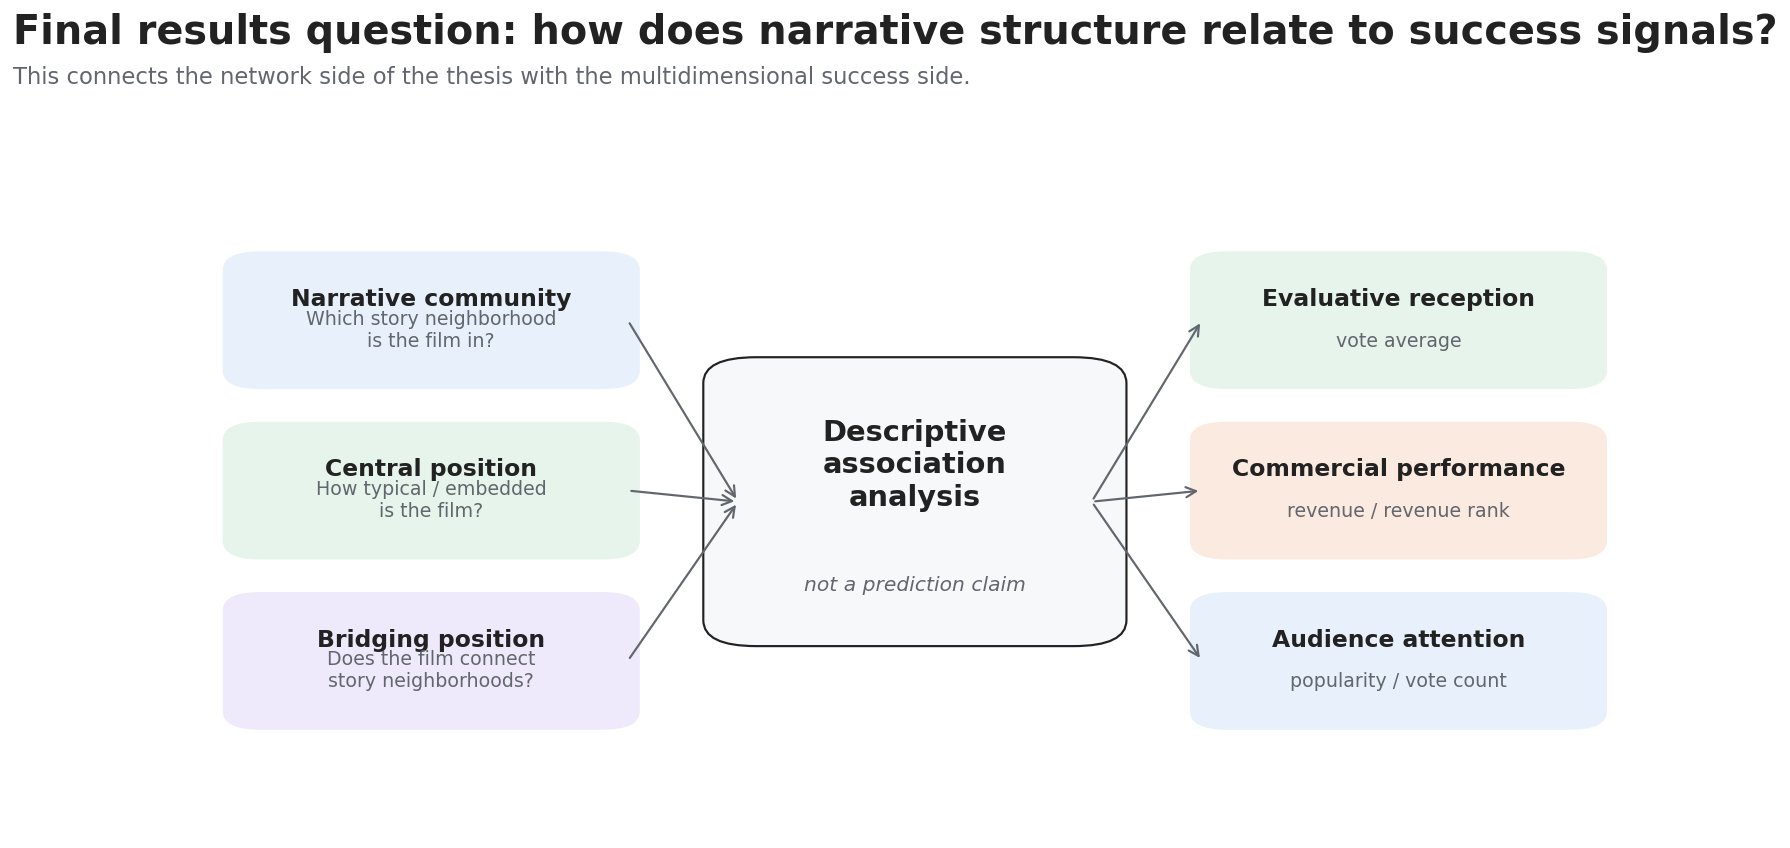

In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 5 — Fig 01: Structure-success question map
# ══════════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(15, 7.4))
ax.axis('off'); ax.set_xlim(0,1); ax.set_ylim(0,1)
title_block(fig, 'Final results question: how does narrative structure relate to success signals?',
            'This connects the network side of the thesis with the multidimensional success side.')

left_items = [
    (.06, .62, 'Narrative community', 'Which story neighborhood\nis the film in?', COL['light_blue']),
    (.06, .39, 'Central position', 'How typical / embedded\nis the film?', COL['light_green']),
    (.06, .16, 'Bridging position', 'Does the film connect\nstory neighborhoods?', COL['light_purple']),
]
right_items = [
    (.70, .62, 'Evaluative reception', 'vote average', COL['light_green']),
    (.70, .39, 'Commercial performance', 'revenue / revenue rank', COL['light_orange']),
    (.70, .16, 'Audience attention', 'popularity / vote count', COL['light_blue']),
]

for x, y, h, b, bg in left_items + right_items:
    ax.add_patch(FancyBboxPatch((x, y), .24, .15, boxstyle='round,pad=.018,rounding_size=.025', facecolor=bg, edgecolor='none'))
    ax.text(x+.12, y+.095, h, ha='center', fontsize=13, fontweight='bold')
    ax.text(x+.12, y+.040, b, ha='center', fontsize=10.5, color=COL['muted'])

ax.add_patch(FancyBboxPatch((.385,.28), .23, .34, boxstyle='round,pad=.025,rounding_size=.035', facecolor=COL['panel'], edgecolor=COL['ink'], linewidth=1.2))
ax.text(.50, .50, 'Descriptive\nassociation\nanalysis', ha='center', va='center', fontsize=16, fontweight='bold')
ax.text(.50, .33, 'not a prediction claim', ha='center', fontsize=11.2, color=COL['muted'], style='italic')

for _, y, *_ in left_items: ax.add_patch(FancyArrowPatch((.31, y+.075), (.383, .45), arrowstyle='->', mutation_scale=14, lw=1.2, color=COL['muted']))
for _, y, *_ in right_items: ax.add_patch(FancyArrowPatch((.617, .45), (.69, y+.075), arrowstyle='->', mutation_scale=14, lw=1.2, color=COL['muted']))

save_fig(fig, '01_structure_success_question_map.png'); plt.show()

  ✓ Saved: 02_success_model_summary.png


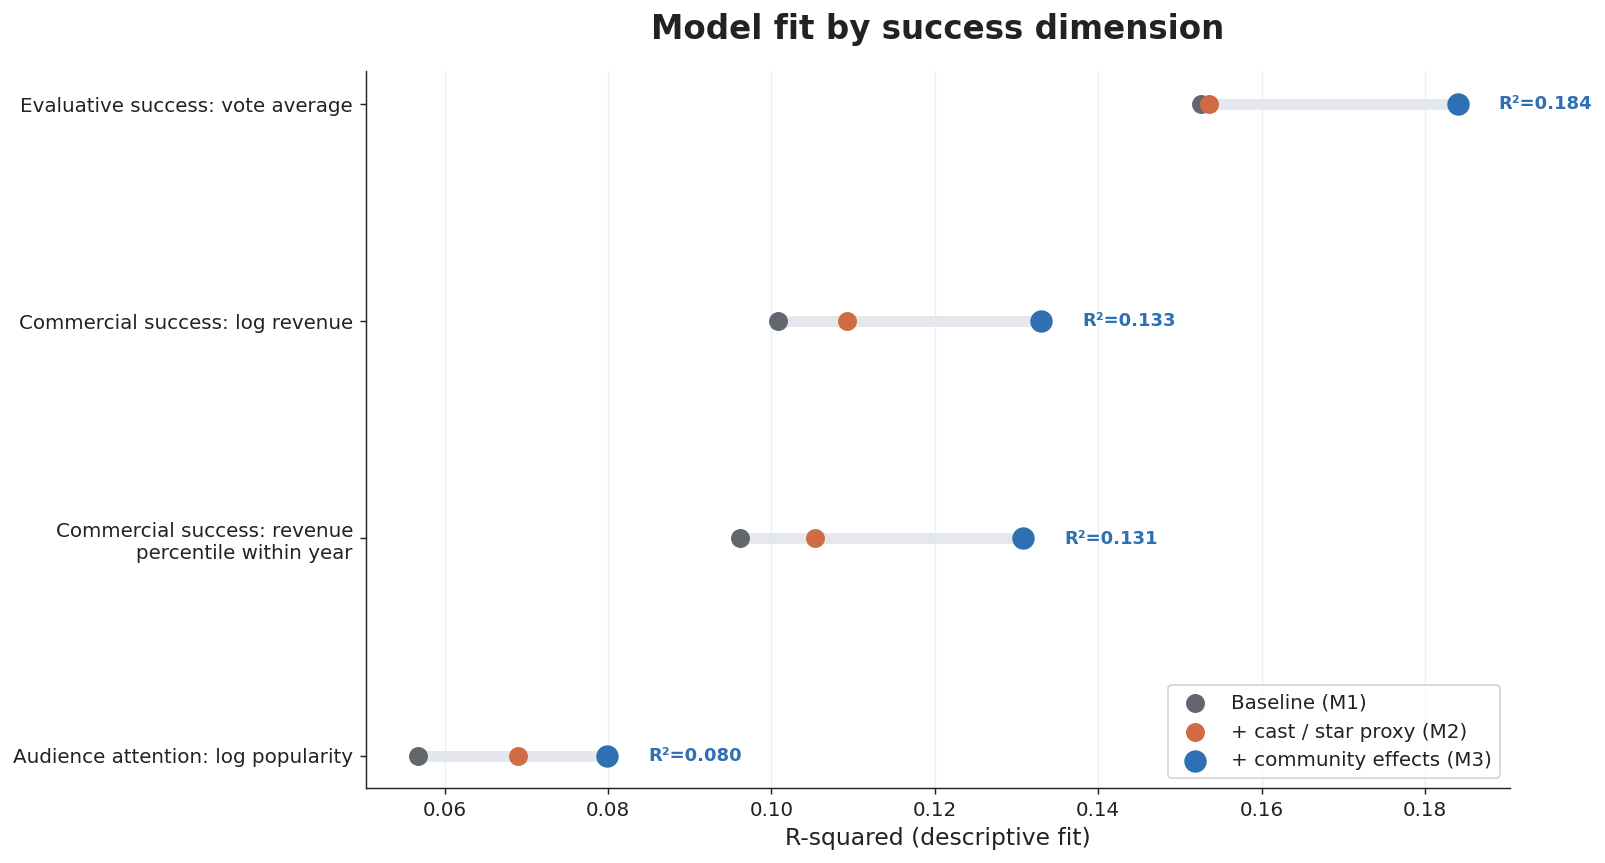

In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 6 — Fig 02: Model R² dot-plot
# ══════════════════════════════════════════════════════════════════════════════
if model_summary is not None and len(model_summary):
    ms = model_summary.copy()
    outcome_col = first_col(ms, ['outcome_label', 'outcome'])
    m1 = first_col(ms, ['M1_network_genre_year', 'model_1', 'baseline_r2'])
    m2 = first_col(ms, ['M2_add_cast_proxy', 'model_2'])
    m3 = first_col(ms, ['M3_add_community_FE', 'model_3', 'best_r2'])

    if outcome_col and m1 and m3:
        ms = ms.sort_values(m3, ascending=True)
        fig, ax = plt.subplots(figsize=(12.5, 6.8))
        y = np.arange(len(ms))

        for yi, (_, r) in zip(y, ms.iterrows()):
            ax.plot([r[m1], r[m3]], [yi, yi], color=COL['grid'], lw=6, solid_capstyle='round', zorder=1)

        ax.scatter(ms[m1], y, s=90, color=COL['muted'], zorder=3, label='Baseline (M1)')
        if m2: ax.scatter(ms[m2], y, s=90, color=COL['orange'], zorder=3, label='+ cast / star proxy (M2)')
        ax.scatter(ms[m3], y, s=130, color=COL['blue'], zorder=4, label='+ community effects (M3)')

        for yi, (_, r) in zip(y, ms.iterrows()):
            ax.text(r[m3]+0.005, yi, f'R²={r[m3]:.3f}', va='center', fontsize=10, fontweight='bold', color=COL['blue'])

        ax.set_yticks(y); ax.set_yticklabels([wrap_text(str(x), 36) for x in ms[outcome_col]])
        ax.set_xlabel('R-squared (descriptive fit)')
        ax.set_title('Model fit by success dimension', pad=18)
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(axis='x', color=COL['grid'], alpha=0.7)
        ax.legend(loc='lower right')
        plt.tight_layout(); save_fig(fig, '02_success_model_summary.png'); plt.show()

  ✓ Saved: 03_community_r2_gain.png


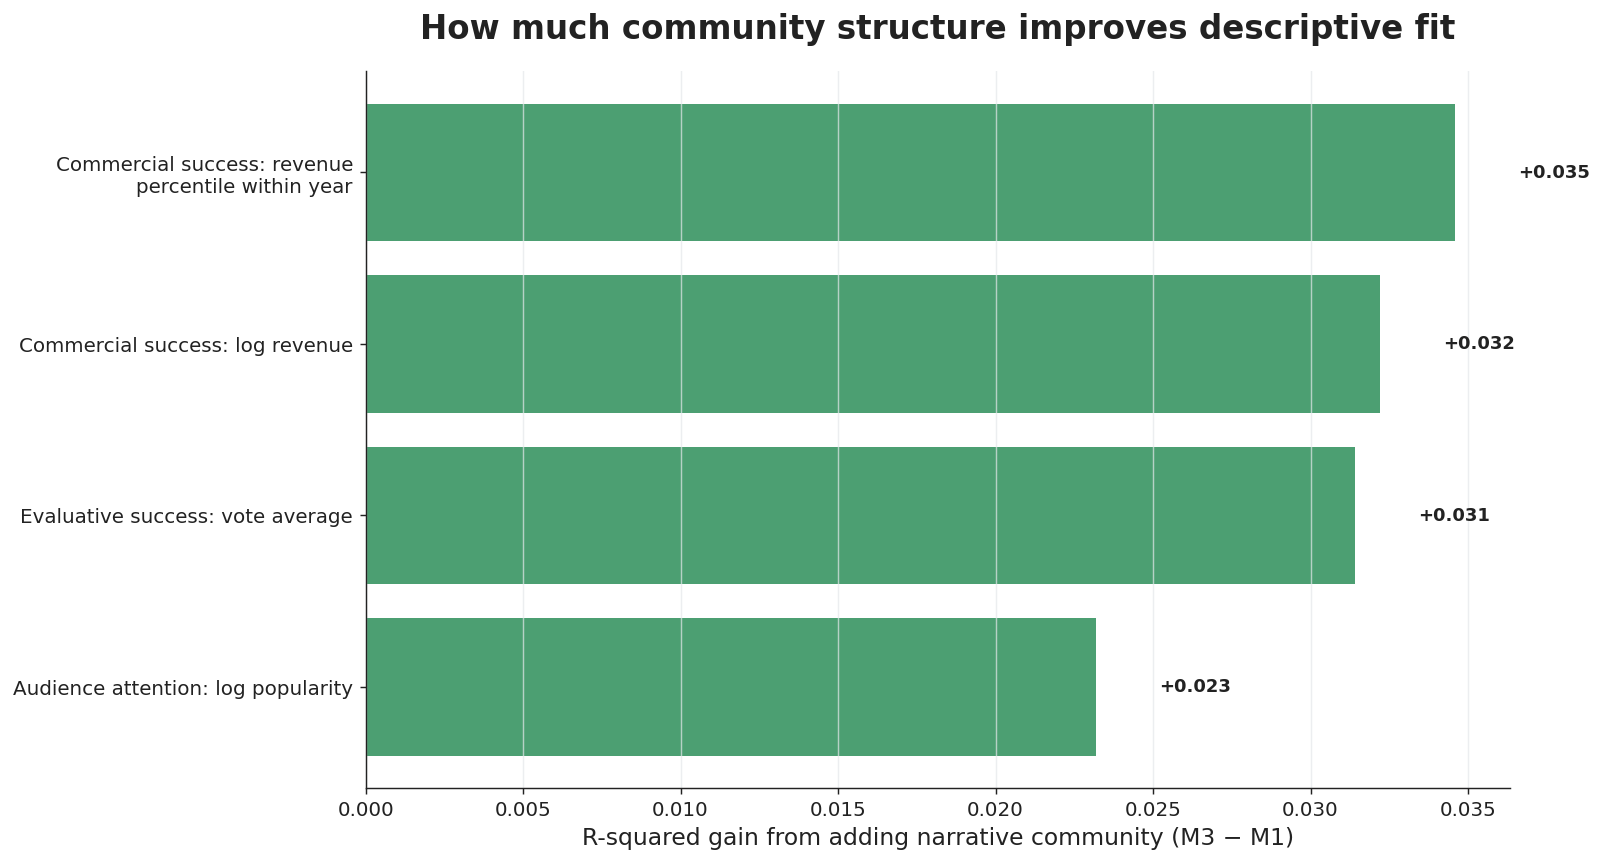

In [7]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 7 — Fig 03: Community R² gain bar chart
# ══════════════════════════════════════════════════════════════════════════════
if model_summary is not None and len(model_summary) and outcome_col and m1 and m3:
    gain = ms.copy()
    gain['community_gain'] = pd.to_numeric(gain[m3], errors='coerce') - pd.to_numeric(gain[m1], errors='coerce')
    gain = gain.dropna(subset=['community_gain']).sort_values('community_gain', ascending=True)

    fig, ax = plt.subplots(figsize=(12.5, 6.8))
    y = np.arange(len(gain))
    colors = [COL['green'] if v >= 0 else COL['red'] for v in gain['community_gain']]

    ax.barh(y, gain['community_gain'], color=colors, alpha=0.86)
    for yi, (_, r) in zip(y, gain.iterrows()):
        sign = '+' if r['community_gain'] >= 0 else ''
        ax.text(r['community_gain'] + 0.002, yi, f'{sign}{r["community_gain"]:.3f}', va='center', fontsize=10, fontweight='bold')

    ax.axvline(0, color=COL['ink'], lw=1.0)
    ax.set_yticks(y); ax.set_yticklabels([wrap_text(str(x), 36) for x in gain[outcome_col]])
    ax.set_xlabel('R-squared gain from adding narrative community (M3 − M1)')
    ax.set_title('How much community structure improves descriptive fit', pad=18)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', color=COL['grid'], alpha=0.7)
    plt.tight_layout(); save_fig(fig, '03_community_r2_gain.png'); plt.show()

  ✓ Saved: 04_community_success_profile_heatmap.png


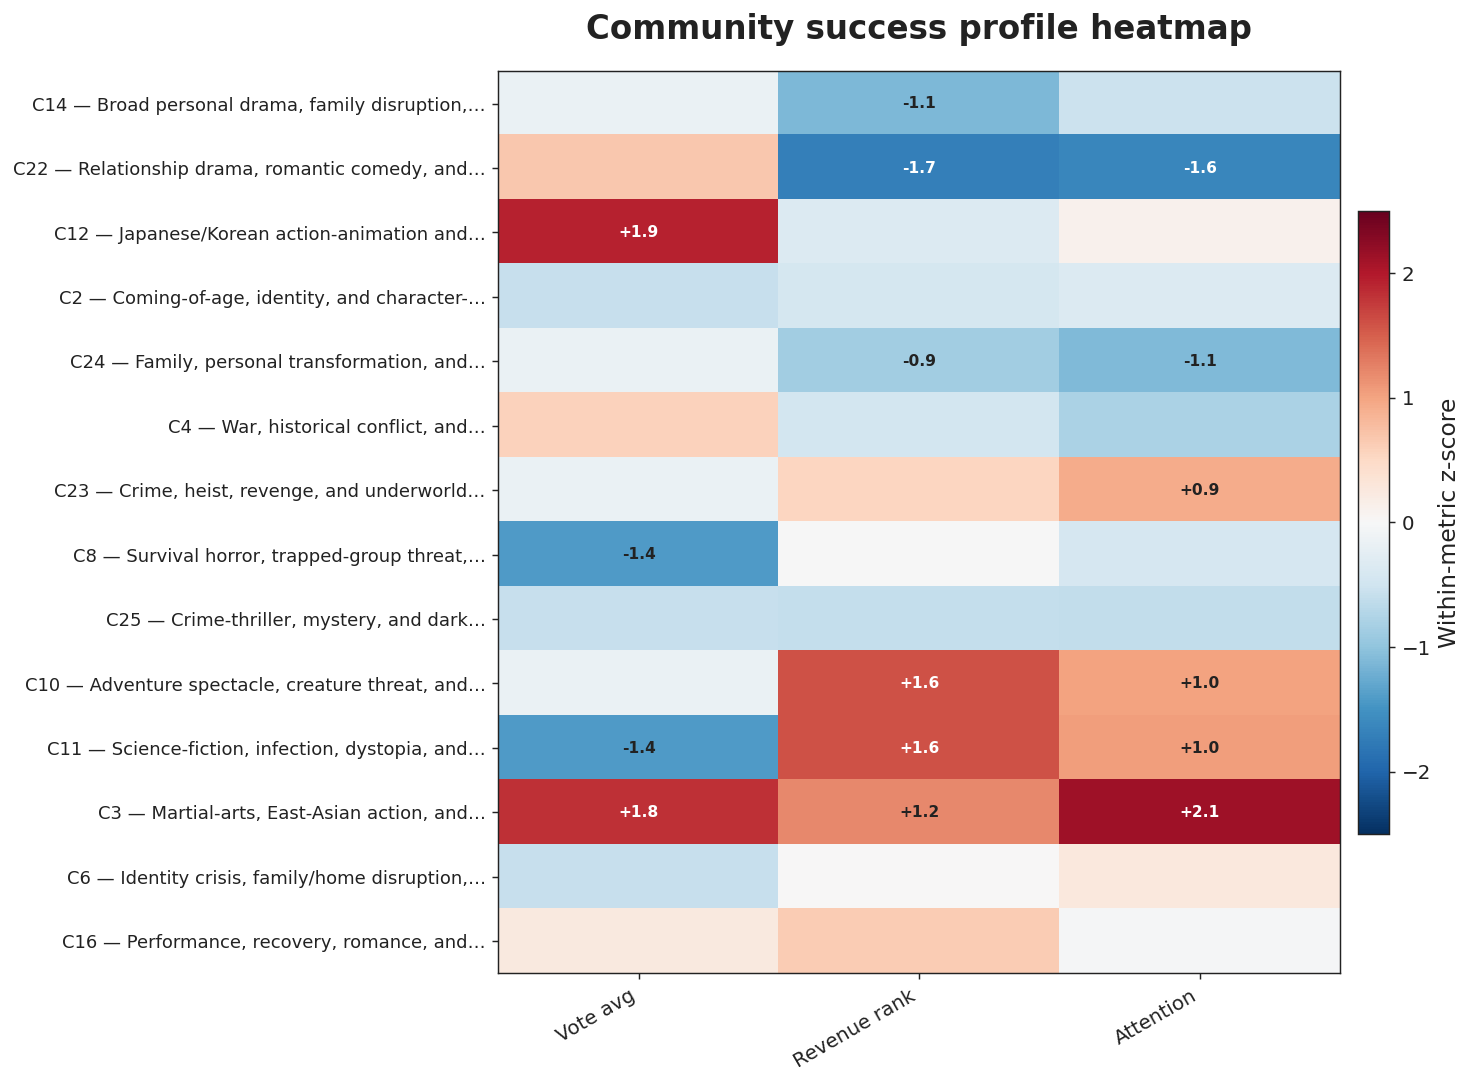

In [8]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 8 — Fig 04: Community success profile heatmap (z-score)
# ══════════════════════════════════════════════════════════════════════════════
if community_success is not None and len(community_success):
    cs = community_success.copy()
    n_col = first_col(cs, ['n_films', 'n_nodes'])
    if n_col: cs = cs[pd.to_numeric(cs[n_col], errors='coerce') >= CFG['min_community_size']]

    metrics = [
        ('Vote avg', first_col(cs, ['median_vote_average', 'vote_average_median'])),
        ('Revenue rank', first_col(cs, ['median_revenue_percentile_year', 'median_revenue_percentile'])),
        ('Revenue', first_col(cs, ['median_log_revenue', 'log_revenue_median'])),
        ('Attention', first_col(cs, ['median_log_popularity', 'median_popularity']))
    ]
    metrics = [(n, c) for n, c in metrics if c]

    if metrics:
        cs_plot = cs.sort_values(n_col, ascending=False).head(CFG['heatmap_top_n']) if n_col else cs.head(CFG['heatmap_top_n'])
        heat = pd.DataFrame(index=range(len(cs_plot)))
        for name, col in metrics: heat[name] = zscore(cs_plot[col]).values

        ylabels = [f"C{int(r['community_id'])} — {shorten(r.get('narrative_label',''), 42)}" for _, r in cs_plot.iterrows()]

        fig, ax = plt.subplots(figsize=(11.5, 8.5))
        im = ax.imshow(heat.values, aspect='auto', cmap='RdBu_r', vmin=-2.5, vmax=2.5)
        ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns, rotation=30, ha='right', fontsize=11)
        ax.set_yticks(range(len(ylabels))); ax.set_yticklabels(ylabels, fontsize=10)

        for i in range(heat.shape[0]):
            for j in range(heat.shape[1]):
                val = heat.iloc[i, j]
                if pd.notna(val) and abs(val) >= 0.8:
                    ax.text(j, i, f'{val:+.1f}', ha='center', va='center', fontsize=8.5, fontweight='bold', color='white' if abs(val) > 1.5 else COL['ink'])

        plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02, label='Within-metric z-score')
        ax.set_title('Community success profile heatmap', pad=18)
        plt.tight_layout(); save_fig(fig, '04_community_success_profile_heatmap.png'); plt.show()

  ✓ Saved: 05_top_communities_evaluative.png


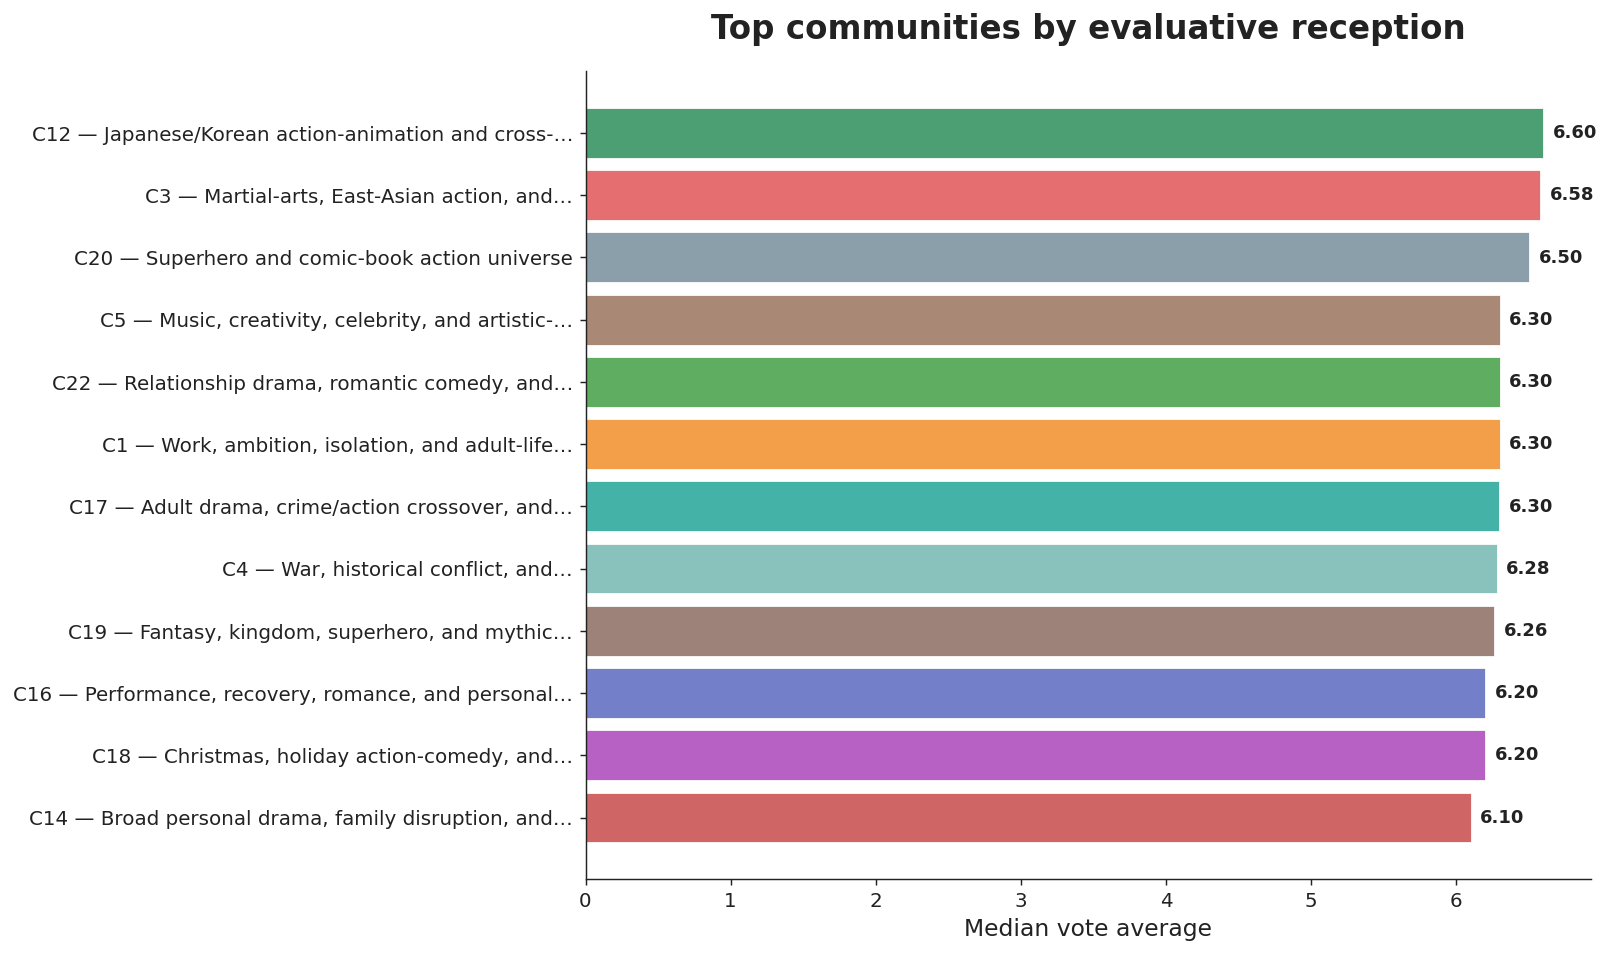

  ✓ Saved: 06_top_communities_commercial.png


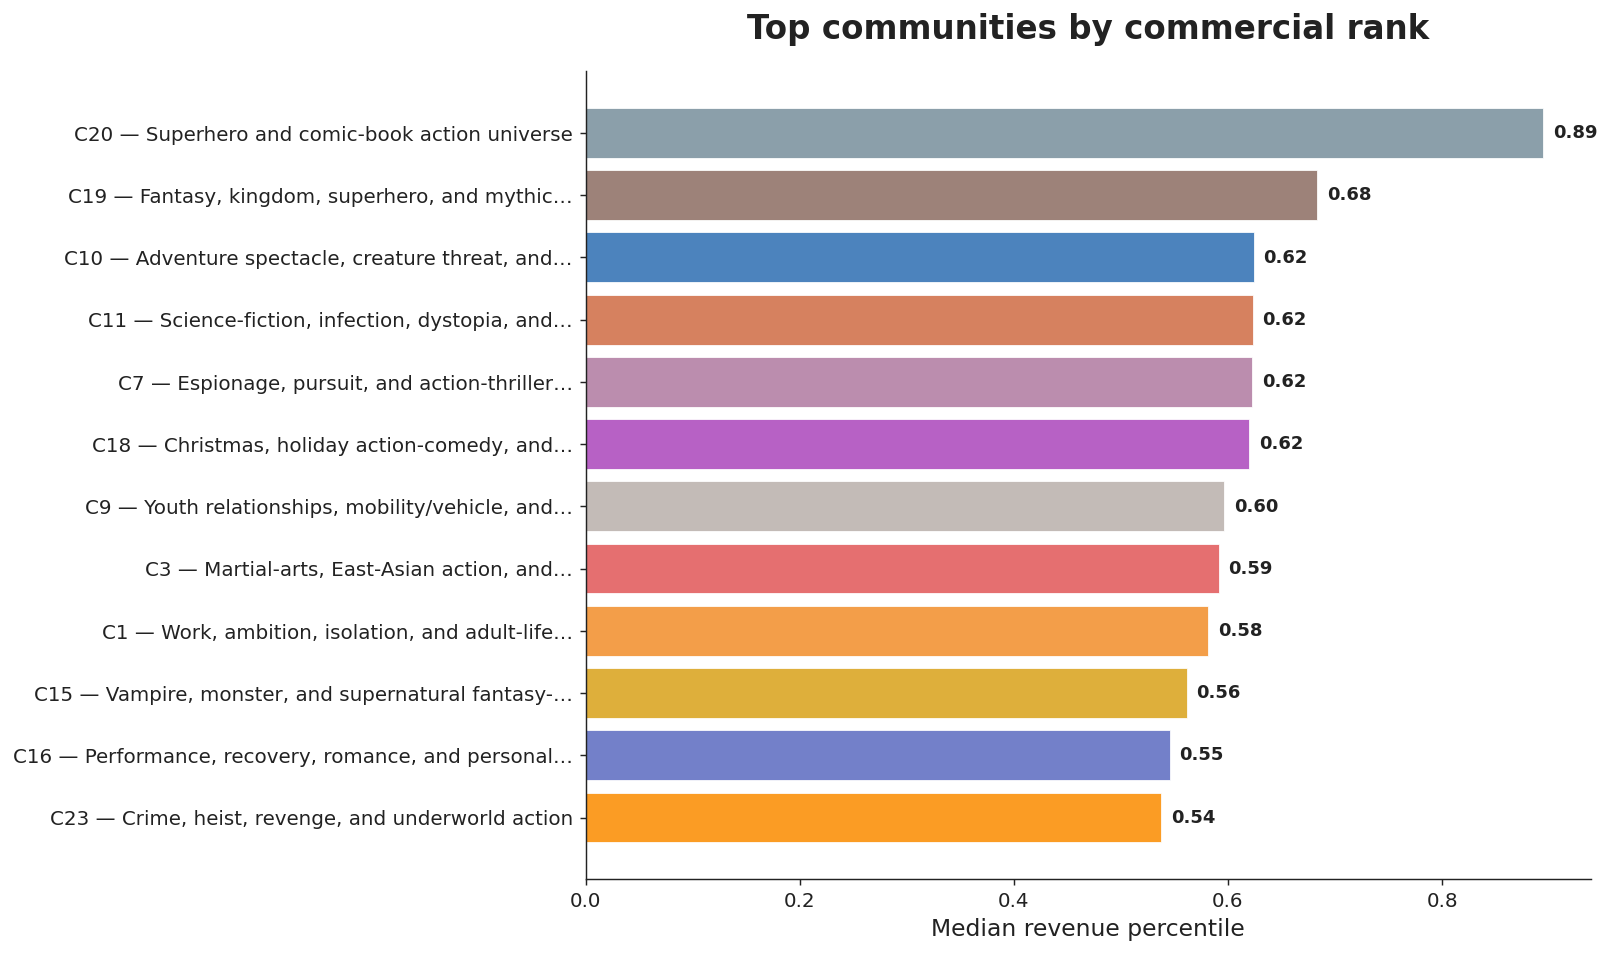

In [9]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 9 — Figs 05 & 06: Top communities by specific success signal
# ══════════════════════════════════════════════════════════════════════════════
def ranked_community_bar(metric_col, title, xlabel, filename):
    if community_success is None or metric_col is None: return
    cs = community_success.copy()
    n_c = first_col(cs, ['n_films', 'n_nodes'])
    if n_c: cs = cs[pd.to_numeric(cs[n_c], errors='coerce') >= CFG['min_community_size']]

    tmp = cs.dropna(subset=[metric_col]).sort_values(metric_col, ascending=True).tail(CFG['ranked_bar_top_n'])
    if len(tmp) == 0: return

    fig, ax = plt.subplots(figsize=(12.5, 7.5))
    labels = [f"C{int(r['community_id'])} — {shorten(r.get('narrative_label',''), 46)}" for _, r in tmp.iterrows()]
    colors = [community_color(c) for c in tmp['community_id']]
    values = pd.to_numeric(tmp[metric_col], errors='coerce')

    bars = ax.barh(labels, values, color=colors, alpha=0.86, edgecolor='white', linewidth=0.5)
    for bar, val in zip(bars, values): ax.text(bar.get_width() + values.max()*0.01, bar.get_y() + bar.get_height()/2, f'{val:.2f}', va='center', fontweight='bold', fontsize=10)

    ax.set_title(title, pad=18); ax.set_xlabel(xlabel)
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout(); save_fig(fig, filename); plt.show()

if community_success is not None:
    ranked_community_bar(first_col(community_success, ['median_vote_average', 'vote_average_median']),
                         'Top communities by evaluative reception', 'Median vote average', '05_top_communities_evaluative.png')
    ranked_community_bar(first_col(community_success, ['median_revenue_percentile_year', 'median_revenue_percentile']),
                         'Top communities by commercial rank', 'Median revenue percentile', '06_top_communities_commercial.png')

  ✓ Saved: 07_centrality_success_profile.png


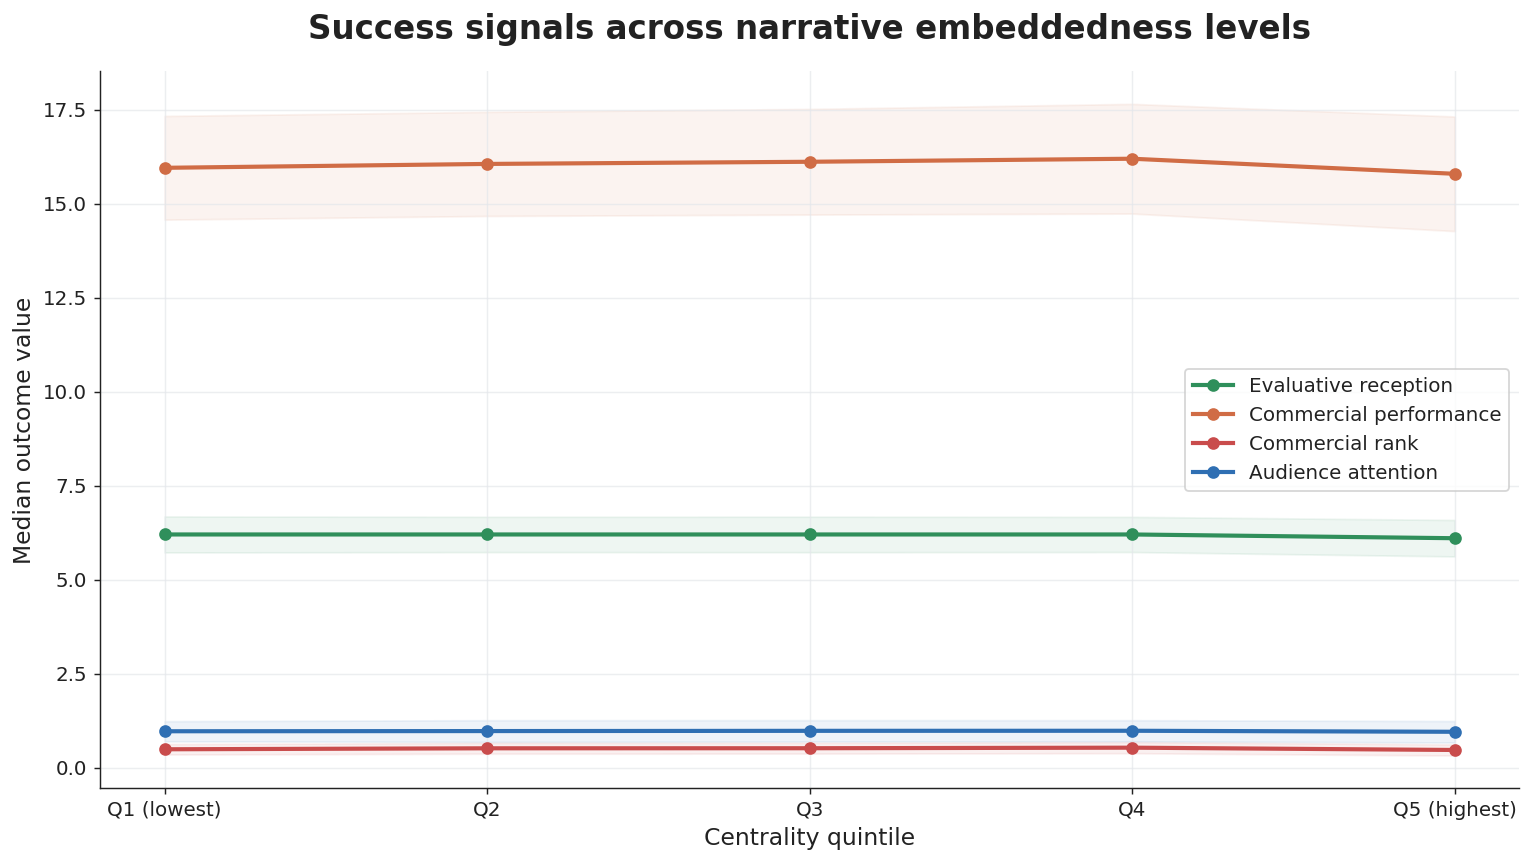

  ✓ Saved: 08_bridging_success_profile.png


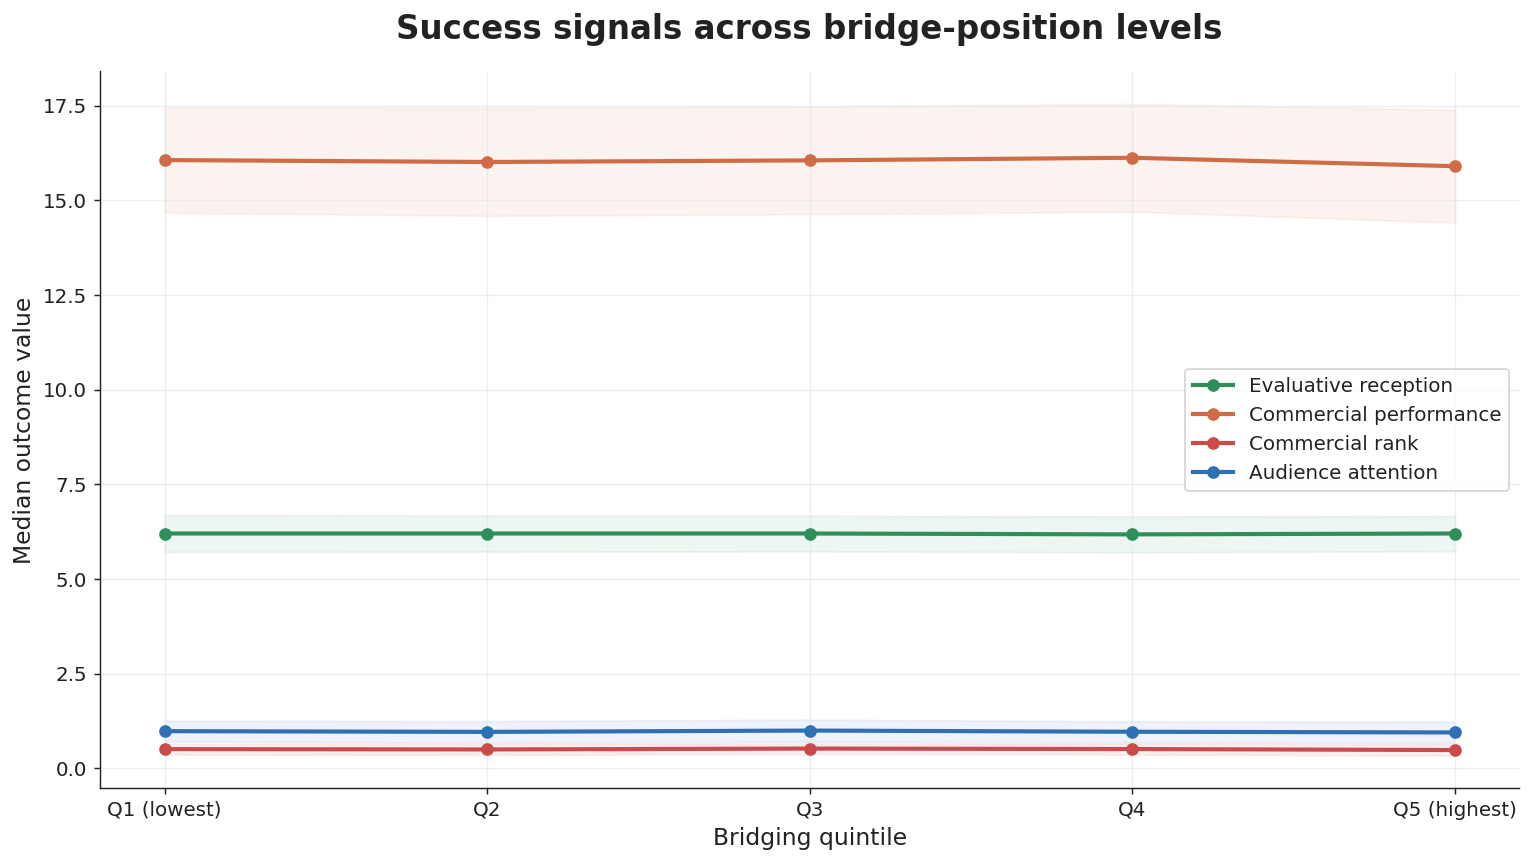

In [10]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 10 — Figs 07 & 08: Centrality and Bridging Profiles
# ══════════════════════════════════════════════════════════════════════════════
def binned_profile_plot(score_col, filename, fig_title, xlabel):
    if score_col is None or not outcomes: return
    temp = df.dropna(subset=[score_col]).copy()
    temp['_bin'] = pd.qcut(temp[score_col].rank(method='first'), q=CFG['binned_quantiles'], labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (highest)'])
    order = ['Q1 (lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (highest)']

    rows = []
    for label, col, color in outcomes:
        if col in temp.columns:
            g = temp.groupby('_bin', observed=True)[col].agg(['median', 'std']).reindex(order).reset_index()
            g['outcome'], g['color'] = label, color
            rows.append(g)

    if not rows: return
    prof = pd.concat(rows, ignore_index=True)

    fig, ax = plt.subplots(figsize=(12, 6.8))
    for label, _, color in outcomes:
        sub = prof[prof['outcome'] == label]
        if len(sub) == 0: continue
        ax.plot(order, sub['median'], marker='o', lw=2.3, color=color, label=label, zorder=3)
        ax.fill_between(range(len(order)), sub['median'] - sub['std']*0.5, sub['median'] + sub['std']*0.5, alpha=0.08, color=color)

    ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
    ax.set_title(fig_title, pad=18); ax.set_xlabel(xlabel); ax.set_ylabel('Median outcome value')
    ax.spines[['top', 'right']].set_visible(False); ax.grid(color=COL['grid'], alpha=0.7); ax.legend(loc='best')
    plt.tight_layout(); save_fig(fig, filename); plt.show()

binned_profile_plot('centrality_pct' if 'centrality_pct' in df.columns else weighted_degree,
                    '07_centrality_success_profile.png', 'Success signals across narrative embeddedness levels', 'Centrality quintile')
binned_profile_plot('bridging_pct' if 'bridging_pct' in df.columns else betweenness,
                    '08_bridging_success_profile.png', 'Success signals across bridge-position levels', 'Bridging quintile')

  ✓ Saved: 09_success_signal_correlation_matrix.png


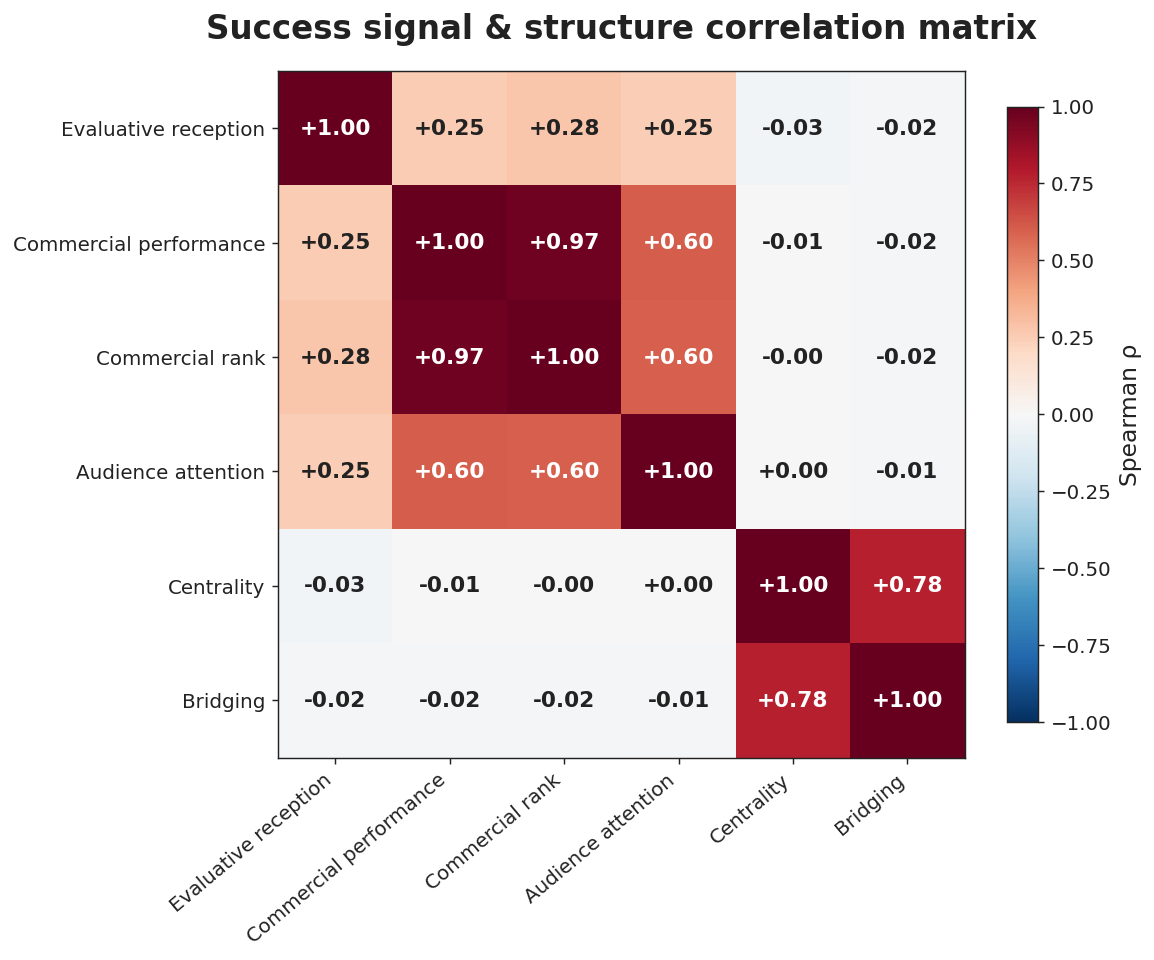

In [11]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 11 — Fig 09: Success signal correlation matrix
# ══════════════════════════════════════════════════════════════════════════════
signal_cols = {name: col for name, col, *_ in outcomes if col and col in df.columns}
struct_cols = {}
if weighted_degree in df.columns: struct_cols['Centrality'] = weighted_degree
if betweenness in df.columns: struct_cols['Bridging'] = betweenness
all_cols = {**signal_cols, **struct_cols}

if len(all_cols) >= 3:
    sub = df[list(all_cols.values())].rename(columns={v: k for k, v in all_cols.items()}).dropna(how='all')
    corr = sub.corr(method='spearman', numeric_only=True)

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=40, ha='right')
    ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)

    for i in range(len(corr)):
        for j in range(len(corr)):
            v = corr.values[i, j]
            ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontweight='bold', color='white' if abs(v) > 0.5 else COL['ink'])

    plt.colorbar(im, ax=ax, label='Spearman ρ', shrink=0.75)
    ax.set_title('Success signal & structure correlation matrix', pad=18)
    plt.tight_layout(); save_fig(fig, '09_success_signal_correlation_matrix.png'); plt.show()

  ✓ Saved: 10_community_success_dispersion.png


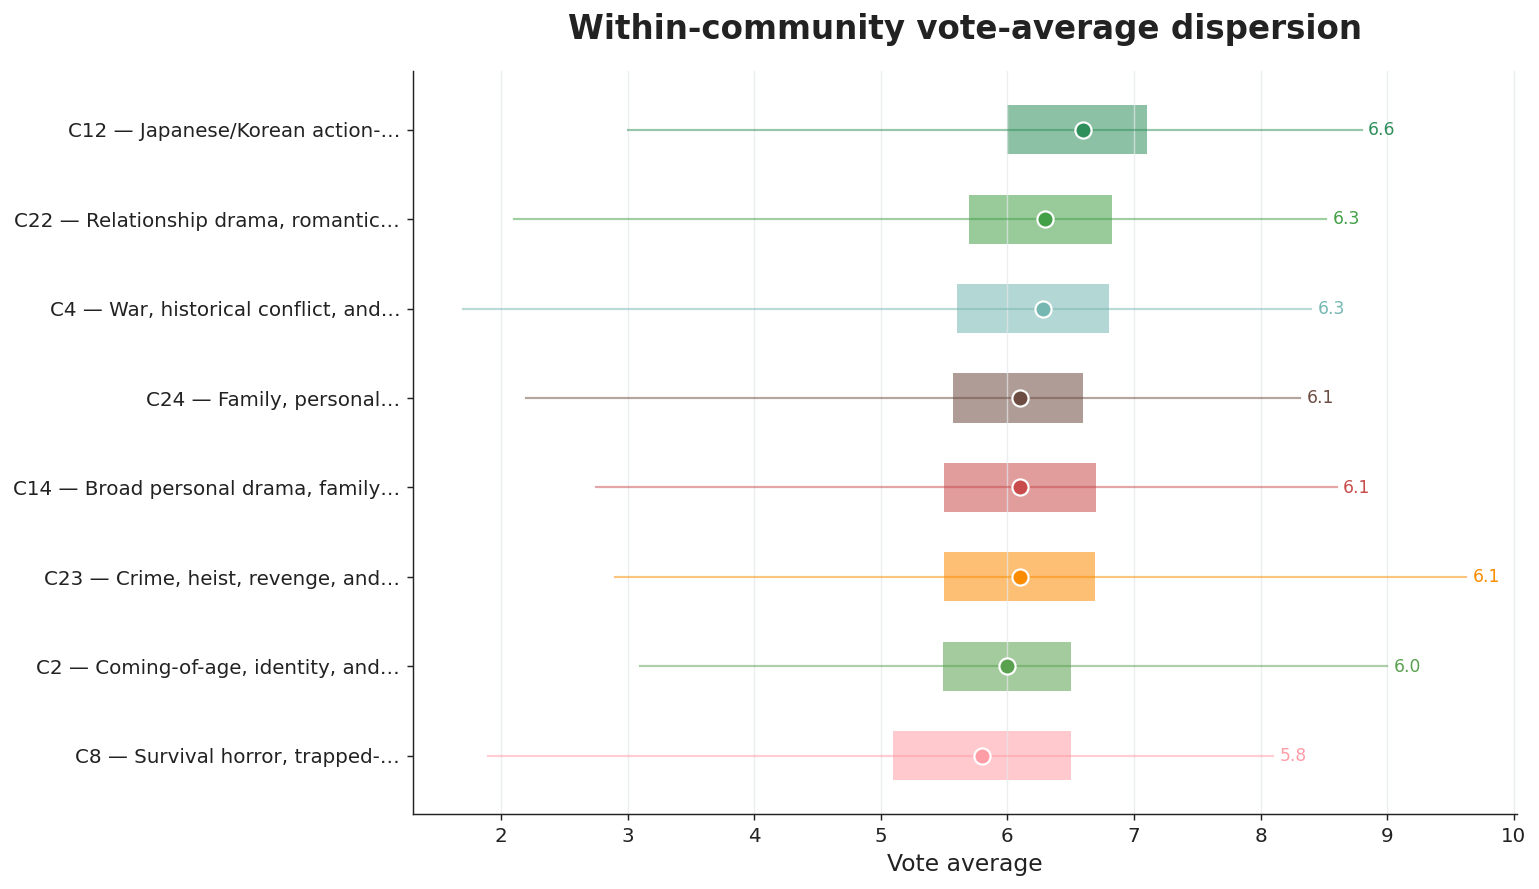

In [12]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 12 — Fig 10: Within-community success dispersion
# ══════════════════════════════════════════════════════════════════════════════
if vote_avg and 'community_id' in df.columns:
    comm_sizes = df.groupby('community_id').size()
    big_comms = comm_sizes[comm_sizes >= CFG['min_community_size']].nlargest(CFG['dispersion_top_n']).index.tolist()
    sub = df[df['community_id'].isin(big_comms)].dropna(subset=[vote_avg]).copy()

    sub['community_label'] = sub.apply(lambda r: f"C{int(r['community_id'])} — {shorten(r.get('narrative_label', ''), 30)}", axis=1)
    order_med = sub.groupby('community_label')[vote_avg].median().sort_values().index.tolist()

    fig, ax = plt.subplots(figsize=(12, 7))
    for i, lbl in enumerate(order_med):
        vals = sub[sub['community_label'] == lbl][vote_avg].values
        med, p25, p75 = np.median(vals), np.percentile(vals, 25), np.percentile(vals, 75)
        color = community_color(sub[sub['community_label'] == lbl]['community_id'].iloc[0])

        ax.barh(i, p75 - p25, left=p25, height=0.55, color=color, alpha=0.55)
        ax.plot([vals.min(), vals.max()], [i, i], color=color, lw=1.2, alpha=0.5)
        ax.scatter(med, i, s=80, color=color, edgecolor='white', lw=1.2, zorder=4)
        ax.text(vals.max() + 0.05, i, f'{med:.1f}', va='center', fontsize=9.5, color=color)

    ax.set_yticks(range(len(order_med))); ax.set_yticklabels(order_med)
    ax.set_xlabel('Vote average'); ax.set_title('Within-community vote-average dispersion', pad=18)
    ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='x', color=COL['grid'], alpha=0.7)
    plt.tight_layout(); save_fig(fig, '10_community_success_dispersion.png'); plt.show()

  ✓ Saved: 11_within_community_centrality_gradient.png


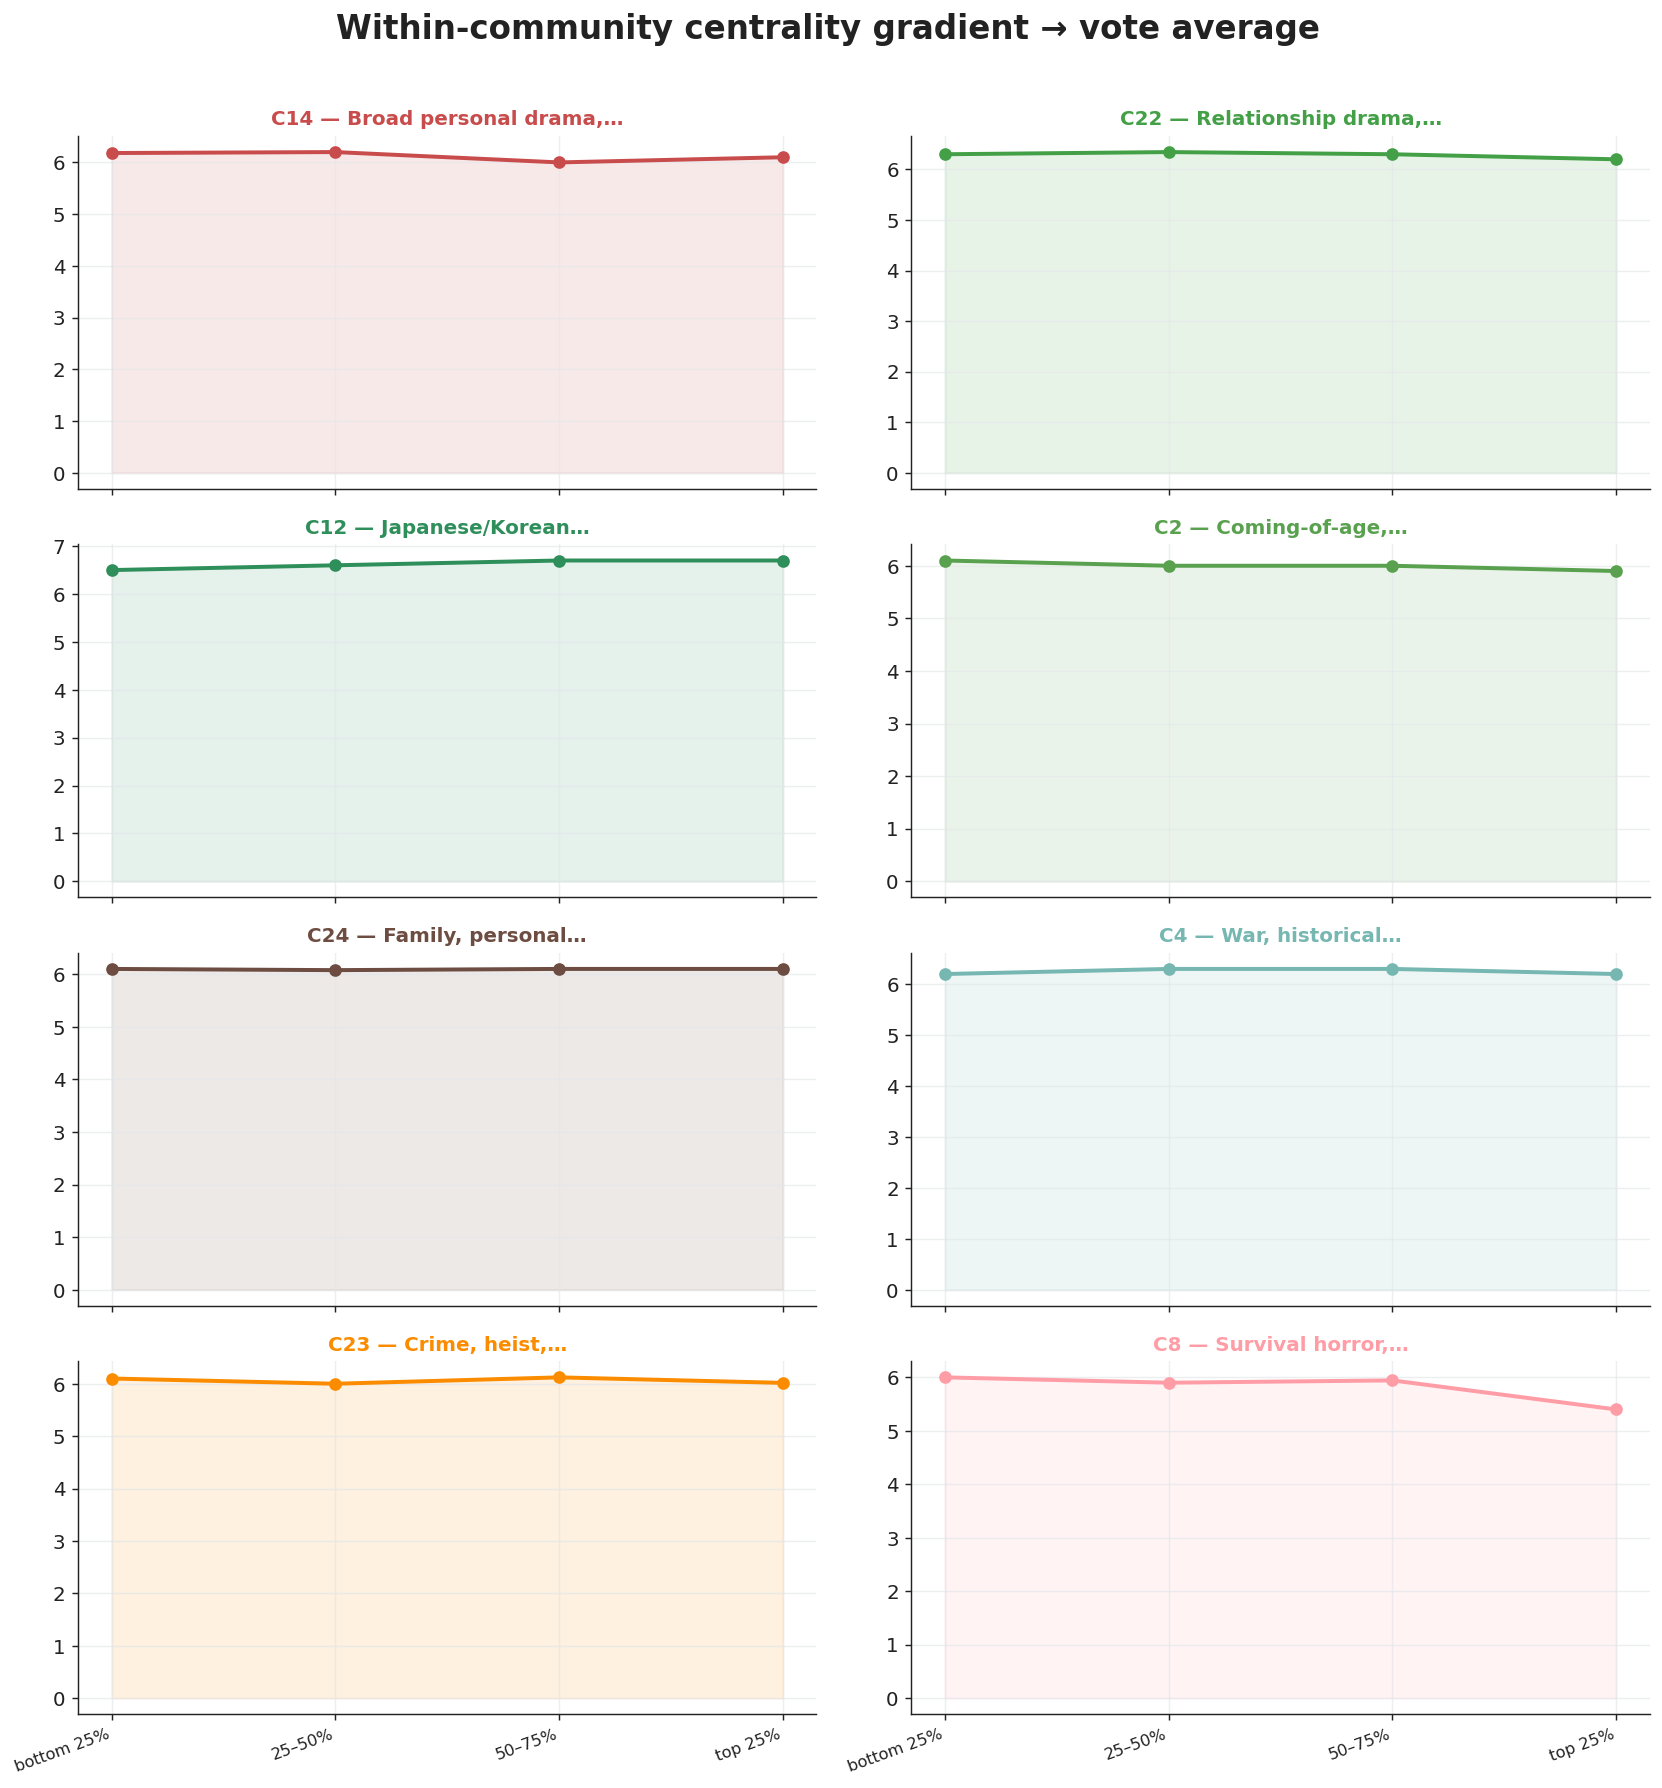

In [13]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 13 — Fig 11: Within-community centrality gradient
# ══════════════════════════════════════════════════════════════════════════════
if weighted_degree and vote_avg and 'community_id' in df.columns:
    rows = []
    for cid in big_comms:
        sub = df[df['community_id'] == cid].dropna(subset=[weighted_degree, vote_avg]).copy()
        if len(sub) < 30: continue
        sub['within_centrality_pct'] = sub[weighted_degree].rank(pct=True, method='min')
        sub['_bin'] = pd.qcut(sub['within_centrality_pct'], q=4, labels=['bottom 25%', '25–50%', '50–75%', 'top 25%'])

        grp = sub.groupby('_bin', observed=True)[vote_avg].median().reset_index().rename(columns={vote_avg: 'median_vote'})
        grp['community_id'], grp['label'] = cid, f"C{int(cid)} — {shorten(sub.get('narrative_label', pd.Series([''])).iloc[0], 22)}"
        rows.append(grp)

    if rows:
        grad = pd.concat(rows, ignore_index=True)
        order = ['bottom 25%', '25–50%', '50–75%', 'top 25%']
        communities = grad['label'].unique()
        ncols = 2; nrows = math.ceil(len(communities) / ncols)

        fig, axes = plt.subplots(nrows, ncols, figsize=(13, 3.4*nrows), sharex=True)
        axes = axes.ravel() if nrows > 1 else [axes] if ncols == 1 else axes.ravel()

        for ax, lbl in zip(axes, communities):
            sub_g = grad[grad['label'] == lbl].set_index('_bin').reindex(order)
            color = community_color(grad[grad['label'] == lbl]['community_id'].iloc[0])
            ax.plot(order, sub_g['median_vote'].values, marker='o', lw=2.2, color=color)
            ax.fill_between(range(4), sub_g['median_vote'].values, alpha=0.12, color=color)
            ax.set_title(lbl, fontsize=11, fontweight='bold', color=color)
            ax.set_xticklabels(order, rotation=20, ha='right', fontsize=9)
            ax.spines[['top', 'right']].set_visible(False); ax.grid(color=COL['grid'], alpha=0.7)

        for ax in axes[len(communities):]: ax.axis('off')
        fig.suptitle('Within-community centrality gradient → vote average', fontsize=18, fontweight='bold', y=1.01)
        plt.tight_layout(); save_fig(fig, '11_within_community_centrality_gradient.png'); plt.show()

  ✓ Saved: 12_key_result_interpretation_cards.png


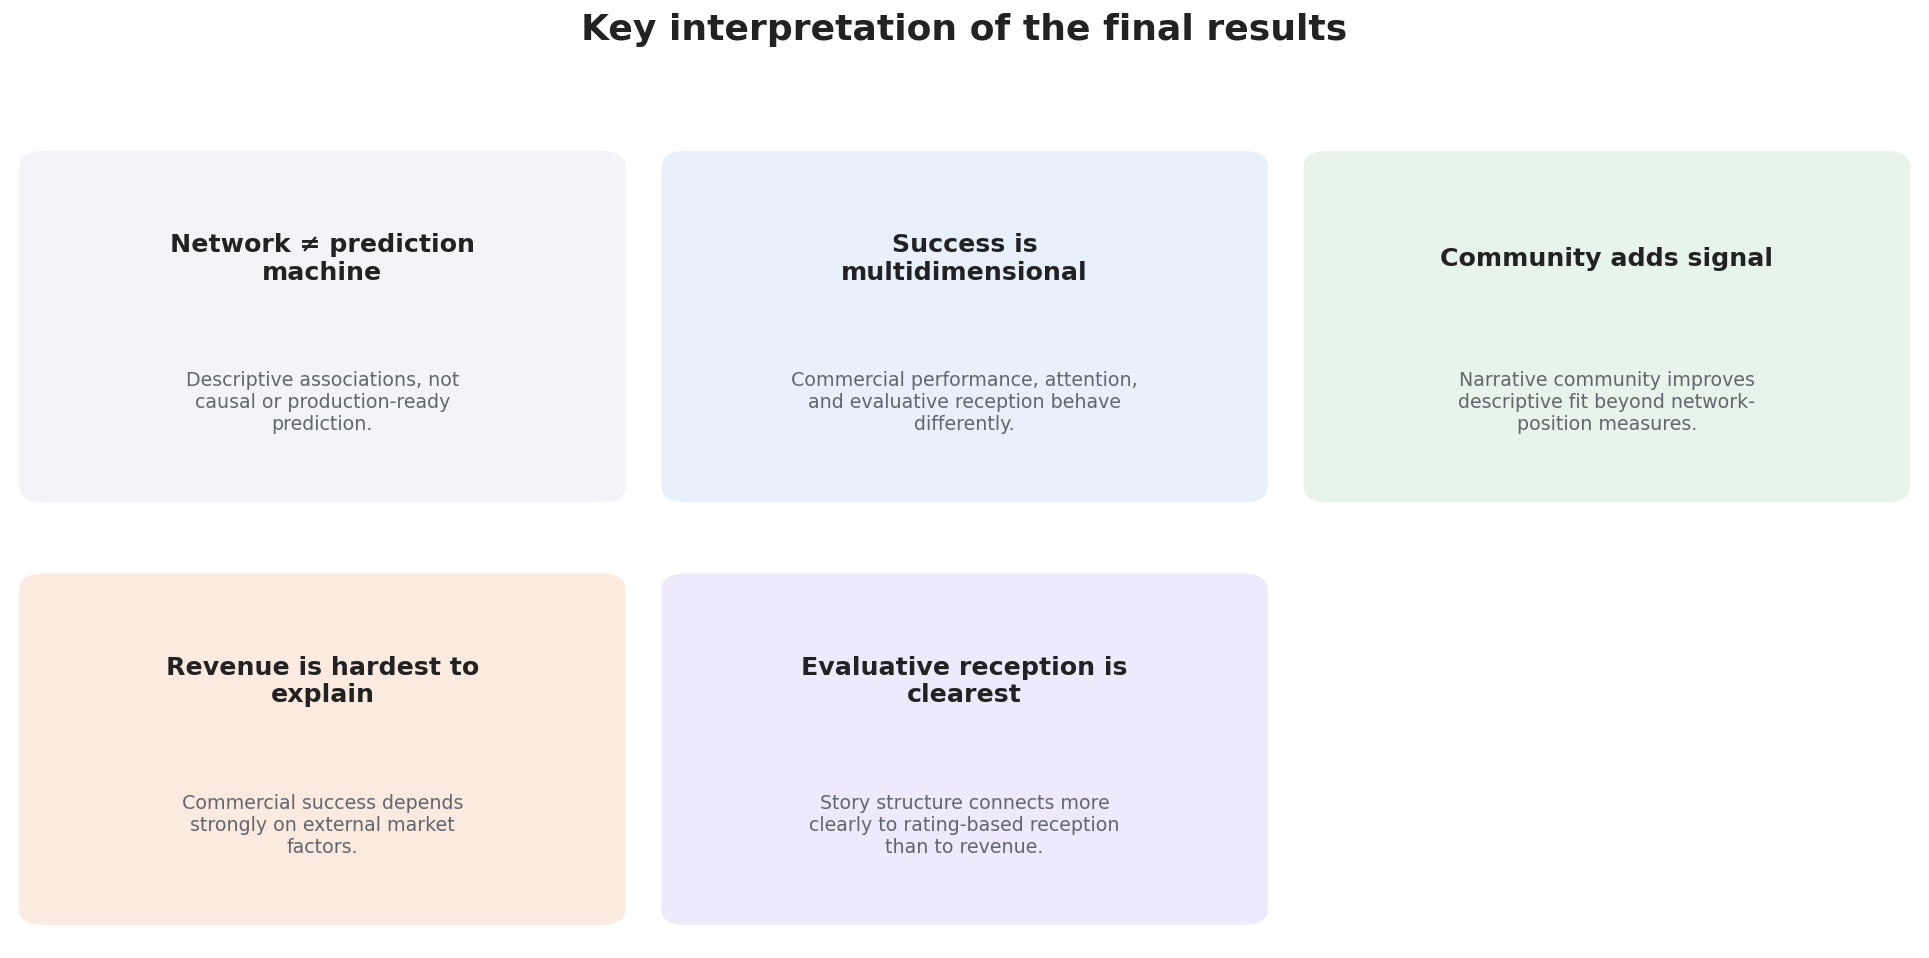

  ✓ Saved: 13_final_results_storyline.png


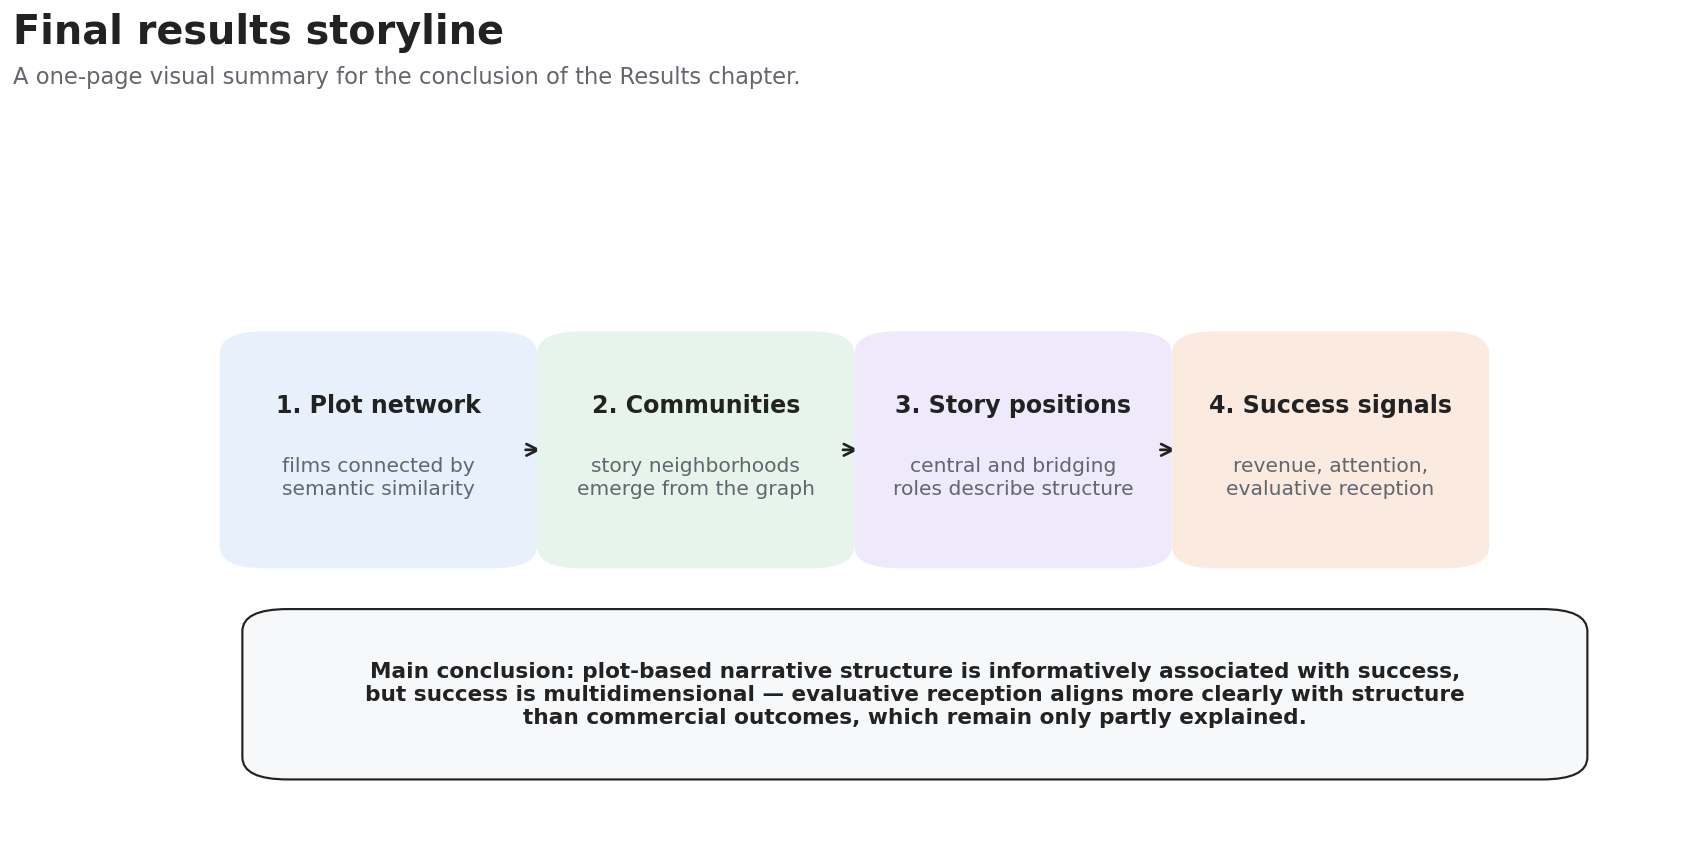

Done!


In [14]:
# ══════════════════════════════════════════════════════════════════════════════
# CELL 14 — Fig 12 & 13: Summary and Storyline
# ══════════════════════════════════════════════════════════════════════════════
cards = [
    ('Network ≠ prediction machine', 'Descriptive associations, not causal or production-ready prediction.', COL['light_gray']),
    ('Success is multidimensional', 'Commercial performance, attention, and evaluative reception behave differently.', COL['light_blue']),
    ('Community adds signal', 'Narrative community improves descriptive fit beyond network-position measures.', COL['light_green']),
    ('Revenue is hardest to explain', 'Commercial success depends strongly on external market factors.', COL['light_orange']),
    ('Evaluative reception is clearest', 'Story structure connects more clearly to rating-based reception than to revenue.', COL['light_purple']),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (h, b, bg) in zip(axes.ravel()[:5], cards):
    ax.axis('off')
    ax.add_patch(FancyBboxPatch((0.04, 0.08), 0.92, 0.82, boxstyle='round,pad=0.03,rounding_size=0.04', facecolor=bg, edgecolor='none'))
    ax.text(0.5, 0.66, wrap_text(h, 24), ha='center', va='center', fontsize=14, fontweight='bold')
    ax.text(0.5, 0.30, wrap_text(b, 34), ha='center', va='center', fontsize=10.5, color=COL['muted'])
axes.ravel()[5].axis('off')
fig.suptitle('Key interpretation of the final results', fontsize=20, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95]); save_fig(fig, '12_key_result_interpretation_cards.png'); plt.show()

fig, ax = plt.subplots(figsize=(15, 7.4)); ax.axis('off'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
title_block(fig, 'Final results storyline', 'A one-page visual summary for the conclusion of the Results chapter.')
steps = [
    (0.06, '1. Plot network', 'films connected by\nsemantic similarity', COL['light_blue']),
    (0.27, '2. Communities', 'story neighborhoods\nemerge from the graph', COL['light_green']),
    (0.48, '3. Story positions', 'central and bridging\nroles describe structure', COL['light_purple']),
    (0.69, '4. Success signals', 'revenue, attention,\nevaluative reception', COL['light_orange']),
]
for i, (x, h, b, bg) in enumerate(steps):
    ax.add_patch(FancyBboxPatch((x, 0.38), 0.17, 0.28, boxstyle='round,pad=0.02,rounding_size=0.03', facecolor=bg, edgecolor='none'))
    ax.text(x+0.085, 0.57, h, ha='center', fontsize=13.2, fontweight='bold')
    ax.text(x+0.085, 0.46, b, ha='center', fontsize=11.2, color=COL['muted'], linespacing=1.25)
    if i < len(steps) - 1: ax.add_patch(FancyArrowPatch((x+0.18, 0.52), (steps[i+1][0]-0.015, 0.52), arrowstyle='->', mutation_scale=16, lw=1.5, color=COL['ink']))

ax.add_patch(FancyBboxPatch((0.08, 0.10), 0.84, 0.18, boxstyle='round,pad=0.025,rounding_size=0.03', facecolor=COL['panel'], edgecolor=COL['ink'], linewidth=1.2))
ax.text(0.5, 0.19, 'Main conclusion: plot-based narrative structure is informatively associated with success,\nbut success is multidimensional — evaluative reception aligns more clearly with structure\nthan commercial outcomes, which remain only partly explained.', ha='center', va='center', fontsize=12.0, color=COL['ink'], fontweight='bold')
save_fig(fig, '13_final_results_storyline.png'); plt.show()
print("Done!")